# 직접 해 보기 2 — 파이썬 코드로 따라 해 보기

AI가 내놓은 결과만 보고 그것이 어떻게 나왔는지 모르면, 그 결과를 믿을 근거도 없다. AI도 실수를 하므로 결과는 점검해야 하고, 점검하려면 결과를 만든 파이썬 코드를 읽을 줄 알아야 한다.

이 노트북은 이 장에서 다룬 계산과 그림을 파이썬으로 직접 해 본다. 보고서의 회귀 결과를 다시 만들고, 계수를 %와 배로 바꾸고, 본문의 표와 그림(변수를 하나씩 더하기, 두 구의 직선, 더미 변수, 상호작용, 제곱항)을 차례로 만든다. 코드는 될 수 있는 한 단순하게 썼다.

1. 데이터 읽기 — 단순회귀분석 장과 같은 CSV를 읽는다
2. 데이터 정리 — 서울 전체 매매에서 변수 다섯 개를 만든다
3. 다중회귀분석 — 보고서의 회귀식을 추정한다
4. 계수를 %와 배로 읽기 — 표 2-1의 마지막 열을 계산한다
5. 가격 계산기 — 아파트 한 채의 조건을 하나씩만 바꾼다
6. 변수를 하나씩 더하기 — 표 2-2를 만든다
7. 두 구의 직선 — 구를 넣으면 면적의 기울기가 왜 바뀌는지 본다
8. 더미 변수 — 스위치를 직접 만들어 보고, 기준 구를 바꿔 본다
9. 상호작용 — 층의 효과가 강남 3구에서 다른지 본다
10. 제곱항 — 연식의 곡선을 읽고, 잔차의 패턴을 비교한다

## 준비 — 패키지와 글꼴

`import`로 쓸 패키지를 불러온다. `as` 뒤의 이름은 줄임말이고, 이후 코드에서는 `np`, `pd`처럼 줄임말로 부른다. 네 패키지는 Anaconda와 Colab에 모두 들어 있다.

matplotlib는 기본 글꼴에 한글이 없어서 그림의 한글이 네모로 깨진다. 그래서 한글 글꼴을 지정한다. 윈도우는 맑은 고딕(`Malgun Gothic`), 맥은 애플고딕(`AppleGothic`)을 쓴다. Colab에는 한글 글꼴이 없으므로 새 셀에서 `!apt-get -qq install fonts-nanum`을 실행하고, 런타임을 다시 시작한 뒤 `NanumGothic`을 지정한다.

In [1]:
import numpy as np                       # 수치 계산
import pandas as pd                      # 표(데이터프레임) 다루기
import statsmodels.formula.api as smf    # 회귀분석
import matplotlib.pyplot as plt          # 그림

# 그림의 한글 글꼴
# 맥은 'AppleGothic', Colab은 'NanumGothic'(설치 필요)
plt.rcParams['font.family'] = 'Malgun Gothic'   # 윈도우
plt.rcParams['axes.unicode_minus'] = False      # 음수 부호(-) 깨짐 방지

## 1. 데이터 읽기

데이터는 단순회귀분석 장과 같은 CSV다(서울 아파트 매매 1년치). 책 사이트의 장 첫 페이지에서 내려받을 수 있다. 국토교통부 실거래가 공개시스템에서 자기 지역이나 다른 기간의 자료를 받는 방법은 단순회귀분석 장의 직접 해 보기 2, "데이터 수집"에 단계별로 적어 두었다.

- 내 컴퓨터의 주피터: CSV를 이 노트북 파일과 같은 폴더에 두고, 아래 코드의 `CSV =` 줄에 파일 이름을 그대로 적는다.
- Colab: 왼쪽의 폴더 아이콘을 누르고 업로드 버튼으로 CSV를 올린 뒤 `CSV = '/content/파일이름.csv'`로 적는다.

`pd.read_csv`의 옵션 셋은 단순회귀분석 장과 같다. 한글 인코딩(`encoding='cp949'`), 표 위의 안내문 15줄(`skiprows=15`), 거래금액의 천 단위 쉼표(`thousands=','`)를 하나씩 맡는다.

In [2]:
CSV = 'seoul-apt-sales-2025-10-2026-10.csv'   # 자기 파일 이름으로 바꾼다

df = pd.read_csv(CSV,
                 encoding='cp949',   # 한글 인코딩
                 skiprows=15,        # 표 위 안내문 15줄 건너뜀
                 thousands=',')      # 51,500 → 51500
print('서울 전체', len(df), '건')

서울 전체 68767 건


## 2. 데이터 정리

보고서의 분석 대상은 "서울 25개 구 아파트 매매, 해제거래 제외"다. 단순회귀분석 장은 노원구만 남겼지만, 이번에는 구로 거르지 않고 서울 전체를 쓴다.

해제거래를 뺀 뒤, 회귀식에 넣을 변수를 만든다. 보고서의 회귀식에 들어가는 변수는 다섯 가지다(면적, 층, 연식, 구, 거래유형).

| 새 변수 | 만드는 법 |
|---|---|
| `가격` | 거래금액(만원) ÷ 10,000 → 억원 |
| `면적` | 전용면적(㎡) 그대로 |
| `층` | 층 그대로 |
| `연식` | 2026 − 건축년도. 2001년에 지은 아파트는 25년 |
| `구` | 시군구("서울특별시 노원구 상계동")를 빈칸으로 나눠 두 번째 낱말 |
| `직거래` | 거래유형이 직거래면 1, 중개거래면 0 |
| `로그가격`, `로그면적` | 가격과 면적의 자연로그 |

- `.str.split()`은 글자를 빈칸에서 나눠 낱말 목록으로 만들고, `.str[1]`은 그 가운데 두 번째(0부터 세므로 1번) 낱말을 꺼낸다.
- `(조건).astype(int)`는 참·거짓을 1과 0으로 바꾼다. 3절에서 본 스위치(더미 변수)를 이렇게 만든다.

In [3]:
d = df[df['해제사유발생일'] == '-'].copy()          # 해제거래 제외

d['가격'] = d['거래금액(만원)'] / 10000              # 만원 → 억원
d['면적'] = d['전용면적(㎡)']
d['연식'] = 2026 - d['건축년도']                     # 지은 지 몇 년
d['구'] = d['시군구'].str.split().str[1]             # "서울특별시 노원구 상계동" → "노원구"
d['직거래'] = (d['거래유형'] == '직거래').astype(int)  # 직거래 1, 중개거래 0
d['로그가격'] = np.log(d['가격'])
d['로그면적'] = np.log(d['면적'])

print('서울 매매', len(d), '건, 구', d['구'].nunique(), '개')
print('중위 가격', round(d['가격'].median(), 1), '억원')
print('직거래', d['직거래'].sum(), '건 (', round(d['직거래'].mean() * 100), '%)')

서울 매매 66589 건, 구 25 개
중위 가격 9.3 억원
직거래 3426 건 ( 5 %)


## 3. 다중회귀분석

보고서의 회귀식을 그대로 옮긴다.

로그(거래가격) = 로그(전용면적) + 층 + 연식 + 연식² + 직거래 + 구 더미 24개 (기준: 노원구)

회귀식을 쓰는 법은 단순회귀분석 장과 같고, `~` 오른쪽에 변수를 `+`로 이어 붙이면 된다. 새로 나오는 표기가 둘 있다.

- `I(연식**2)`: 연식의 제곱(`**2`)을 회귀식 안에서 계산해 변수로 넣는다. `I( )`로 감싸야 식 안의 계산으로 읽힌다(5절의 제곱항).
- `C(구, Treatment('노원구'))`: `구`가 숫자가 아니라 이름이므로 구마다 스위치를 만들어 넣으라는 뜻이다. `Treatment('노원구')`는 노원구를 기준 구로 정한다(3절의 더미 변수). 이 한 줄이 구 더미 24개를 만든다.

회귀식이 길어서 문자열로 따로 적어 두고 쓴다. 뒤의 절에서도 다시 쓴다.

In [4]:
GU = "C(구, Treatment('노원구'))"    # 구 더미 24개, 기준은 노원구
formula = '로그가격 ~ 로그면적 + 층 + 연식 + I(연식**2) + 직거래 + ' + GU

m = smf.ols(formula, data=d).fit()
print(m.summary())

                            OLS Regression Results                            
Dep. Variable:                   로그가격   R-squared:                       0.738
Model:                            OLS   Adj. R-squared:                  0.738
Method:                 Least Squares   F-statistic:                     6475.
Date:                Wed, 14 Oct 2026   Prob (F-statistic):               0.00
Time:                        10:55:21   Log-Likelihood:                -21602.
No. Observations:               66589   AIC:                         4.326e+04
Df Residuals:                   66559   BIC:                         4.354e+04
Df Model:                          29                                         
Covariance Type:            nonrobust                                         
                                     coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
Intercept   

summary의 표가 길다. 구 더미 24개가 `C(구, Treatment('노원구'))[T.강남구]`처럼 한 줄씩 나오기 때문이다. `[T.강남구]`는 "강남구 스위치"라는 뜻이다. 보고서는 이 가운데 강남구 하나만 표에 싣고, 나머지는 그림의 왼쪽 패널로 대신했다.

보고서의 회귀 결과 표에 실린 숫자만 꺼내 본다. `m.params`(추정값), `m.bse`(표준오차), `m.tvalues`($t$값)에서 이름으로 고른다. 잔차 표준오차는 단순회귀분석 장과 같이 `m.mse_resid`의 제곱근이다. 로그 단위라서 `np.exp`로 되돌리면 "같은 조건에서도 실제 가격은 예측값의 0.7배에서 1.4배 사이로 흩어진다"는 보고서의 문장이 나온다.

In [5]:
names = ['로그면적', '층', '연식', 'I(연식 ** 2)', '직거래', GU + '[T.강남구]']
table = pd.DataFrame({'추정값': m.params[names],
                      '표준오차': m.bse[names],
                      't값': m.tvalues[names]})
print(table.round(5))

print('n =', int(m.nobs), ' R² =', round(m.rsquared, 3))
print('잔차 표준오차', round(np.sqrt(m.mse_resid), 2), '(로그)')
print('같은 조건에서 실제 가격의 흩어짐: 예측값의', round(np.exp(-np.sqrt(m.mse_resid)), 1), '배 ~', round(np.exp(np.sqrt(m.mse_resid)), 1), '배')

                                   추정값     표준오차         t값
로그면적                           0.94108  0.00339  277.39693
층                              0.01074  0.00021   50.41052
연식                            -0.04076  0.00044  -93.33964
I(연식 ** 2)                     0.00078  0.00001   86.13315
직거래                           -0.35802  0.00649  -55.14439
C(구, Treatment('노원구'))[T.강남구]  1.02794  0.00771  133.26830
n = 66589  R² = 0.738
잔차 표준오차 0.33 (로그)
같은 조건에서 실제 가격의 흩어짐: 예측값의 0.7 배 ~ 1.4 배


## 4. 계수를 %와 배로 읽기

가격에 로그를 취했으므로 계수는 %와 배로 읽는다(2절의 "로그 다시 보기", 3절의 "몇 배로 읽기").

- 면적: 가격과 면적에 모두 로그가 붙어 계수가 곧 탄력성이다. 면적이 1% 넓으면 가격이 0.94% 높다.
- 그 밖의 계수 $d$: 가격이 $e^d$배가 된다. %로는 $(e^d - 1) \times 100$이다. `np.exp(d)`가 $e^d$를 계산한다.

계수가 작으면 어림셈(계수 × 100%)과 정확한 값이 거의 같지만, 크면 크게 다르다. 층, 직거래, 강남구로 비교해 본다.

In [6]:
for label, name in [('층', '층'), ('직거래', '직거래'), ('강남구', GU + '[T.강남구]')]:
    b = m.params[name]
    print(label, ' 계수', round(b, 4),
          ' 어림셈', round(b * 100, 1), '%',
          ' 정확', round((np.exp(b) - 1) * 100, 1), '%',
          ' 배수', round(np.exp(b), 2))

층  계수 0.0107  어림셈 1.1 %  정확 1.1 %  배수 1.01
직거래  계수 -0.358  어림셈 -35.8 %  정확 -30.1 %  배수 0.7
강남구  계수 1.0279  어림셈 102.8 %  정확 179.5 %  배수 2.8


같은 계산을 구 더미 24개 전체에 하면 표 2-1의 "노원구의 몇 배" 열이 나온다. 이 숫자들을 구마다 점 하나로 그린 것이 보고서의 그림 왼쪽 패널이다. 노원구는 기준이라 1이다.

- `m.params.filter(like='[T.')`는 이름에 `[T.`가 든 계수, 곧 구 더미만 고른다.
- `.str.extract(r'T\.(.+)\]')`는 긴 이름에서 구 이름만 떼어 낸다.

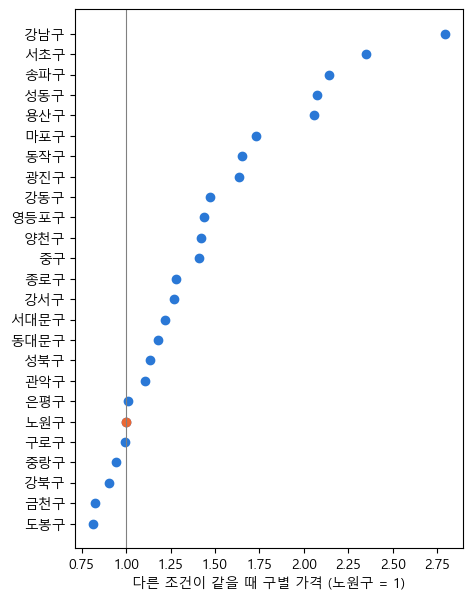

In [7]:
gu = m.params.filter(like='[T.')                     # 구 더미 24개
gu.index = gu.index.str.extract(r'T\.(.+)\]')[0]    # 이름 → 구 이름만
times = np.exp(gu).sort_values()                     # 노원구의 몇 배
times['노원구'] = 1.0                                 # 기준 구
times = times.sort_values()

plt.figure(figsize=(5, 7))
plt.scatter(times, range(len(times)), color='#2a78d6')
plt.scatter([1.0], [list(times.index).index('노원구')], color='#eb6834')   # 노원구는 주황
plt.yticks(range(len(times)), times.index)
plt.axvline(1, color='gray', linewidth=0.8)
plt.xlabel('다른 조건이 같을 때 구별 가격 (노원구 = 1)')
plt.show()

## 5. 가격 계산기

2절의 "계산 속의 실험실"이다. 회귀식은 일종의 가격 계산기라서, 조건을 넣으면 예상 가격이 나온다. `m.predict(표)`가 표의 행마다 예상 로그가격을 계산하고, `np.exp`로 억원으로 되돌린다.

기준 아파트(노원구, 84㎡, 10층, 26년, 중개거래)를 한 행으로 만든 뒤, 조건을 하나씩만 바꾼 행을 덧붙인다. 회귀식에 로그면적이 들어 있으므로 면적을 넣을 때도 로그를 취해 넣는다.

계산기에서 나온 가격의 비율은 4절의 %, 배와 같아야 한다. 층 열 개면 1.1%씩 열 번, 직거래는 30% 싸고, 강남구는 2.8배다.

In [8]:
def apt(구='노원구', 면적=84, 층=10, 연식=26, 직거래=0):
    # 아파트 한 채를 회귀식에 넣을 수 있는 한 행으로 만든다
    return dict(구=구, 로그면적=np.log(면적), 층=층, 연식=연식, 직거래=직거래)

cases = pd.DataFrame([apt(),                    # 기준
                      apt(층=20),               # 층만
                      apt(면적=84 * 1.1),       # 면적만 10% 넓게
                      apt(직거래=1),            # 거래유형만
                      apt(구='강남구'),         # 구만
                      apt(연식=5)],             # 연식만
                     index=['기준', '층 20', '면적 +10%', '직거래', '강남구', '연식 5년'])

price = np.exp(m.predict(cases))                # 예상 가격 (억원)
print(pd.DataFrame({'예상 가격(억원)': price.round(1),
                    '기준 대비': (price / price['기준']).round(2)}))

         예상 가격(억원)  기준 대비
기준             8.1   1.00
층 20           9.1   1.11
면적 +10%        8.9   1.09
직거래            5.7   0.70
강남구           22.8   2.80
연식 5년         11.5   1.41


## 6. 변수를 하나씩 더하기

2절의 표 2-2를 만든다. 직거래 하나만 넣은 회귀식에서 출발해 변수를 하나씩 더하며 회귀분석을 다시 하고, 그때마다 세 숫자를 꺼낸다.

- 직거래가 싼 정도: 직거래 계수 $d$로 $(1 - e^d) \times 100$. "싸다"는 말이 방향을 담으므로 양수로 쓴다.
- 면적 탄력성: 로그면적의 계수. (1)에는 면적이 없으므로 빈칸이다.
- $R^2$

회귀식 다섯 개를 목록에 담고 `for`로 차례로 추정한다. 마지막 회귀식이 3절의 보고서 회귀식이다. 단순 비교 48%가 면적을 맞추면 11%로 줄었다가 30%까지 다시 커지고, 면적 탄력성이 1.00 → 1.00 → 0.89 → 0.94로 움직이는 것을 확인한다.

In [9]:
steps = [('(1) 직거래만',  '로그가격 ~ 직거래'),
         ('(2) + 면적',    '로그가격 ~ 직거래 + 로그면적'),
         ('(3) + 층, 연식', '로그가격 ~ 직거래 + 로그면적 + 층 + 연식'),
         ('(4) + 구',      '로그가격 ~ 직거래 + 로그면적 + 층 + 연식 + ' + GU),
         ('(5) + 연식²',   '로그가격 ~ 직거래 + 로그면적 + 층 + 연식 + I(연식**2) + ' + GU)]

rows = {}
for name, f in steps:
    mk = smf.ols(f, data=d).fit()
    area = f"{mk.params['로그면적']:.2f}" if '로그면적' in mk.params else ''   # (1)에는 면적이 없다
    rows[name] = {'직거래가 싼 정도': f"{(1 - np.exp(mk.params['직거래'])) * 100:.0f}%",
                  '면적 탄력성': area,
                  'R²': f"{mk.rsquared:.2f}"}
pd.DataFrame(rows)

,(1) 직거래만,(2) + 면적,"(3) + 층, 연식",(4) + 구,(5) + 연식²
직거래가 싼 정도,48%,11%,18%,20%,30%
면적 탄력성,,1.00,1.00,0.89,0.94
R²,0.05,0.42,0.45,0.71,0.74


## 7. 두 구의 직선

2절의 그림 2-2다. 노원구와 강남구의 거래만 남겨 두 회귀식을 비교한다.

- 구를 넣지 않은 회귀식(`로그가격 ~ 로그면적`): 두 구를 한데 섞어 직선 하나를 긋는다.
- 구를 넣은 회귀식(`로그가격 ~ 로그면적 + C(구)`): 구마다 높이가 다른 평행선 두 개를 긋는다.

두 축이 모두 로그라서 직선의 기울기가 곧 면적 탄력성이다. 한데 섞으면 기울기가 1.27로 가팔라지고, 구를 넣으면 0.94로 내려온다. 넓은 아파트가 비싼 구(강남구)에 많아서, 구를 빼면 면적이 입지의 몫까지 떠안기 때문이다(누락 변수 편의).

점은 구마다 500건만 무작위로 뽑아 그린다. 다 그리면 점이 너무 겹친다. `.sample(500, random_state=…)`가 무작위로 뽑고, `random_state`를 정해 두면 몇 번을 실행해도 같은 점이 뽑힌다.

한데 섞은 기울기 1.27
구를 넣은 기울기 0.94


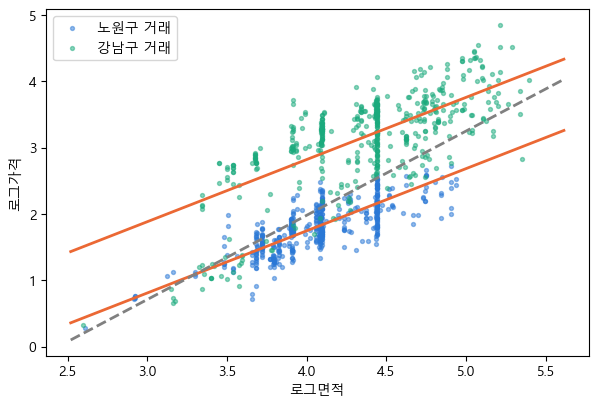

In [10]:
s = d[d['구'].isin(['노원구', '강남구'])]               # 두 구만

pooled = smf.ols('로그가격 ~ 로그면적', data=s).fit()          # 한데 섞은 직선
within = smf.ols('로그가격 ~ 로그면적 + C(구)', data=s).fit()  # 구마다 평행선
print('한데 섞은 기울기', round(pooled.params['로그면적'], 2))
print('구를 넣은 기울기', round(within.params['로그면적'], 2))

plt.figure(figsize=(7, 4.5))
for g, col in [('노원구', '#2a78d6'), ('강남구', '#1baa7d')]:
    pts = s[s['구'] == g].sample(500, random_state=1)
    plt.scatter(pts['로그면적'], pts['로그가격'], s=8, alpha=0.5, color=col, label=g + ' 거래')
    xs = np.linspace(s['로그면적'].min(), s['로그면적'].max(), 50)
    plt.plot(xs, within.predict(pd.DataFrame({'로그면적': xs, '구': g})), color='#eb6834', linewidth=2)
plt.plot(xs, pooled.predict(pd.DataFrame({'로그면적': xs})), color='gray', linestyle='--', linewidth=2)
plt.xlabel('로그면적')
plt.ylabel('로그가격')
plt.legend()
plt.show()

## 8. 더미 변수

3절의 표 3-1을 직접 만들어 본다. `pd.get_dummies`는 이름 변수를 구마다 0과 1의 스위치로 바꾼다. 회귀식의 `C(구, …)`가 속에서 하는 일이 이것이다. 노원구 거래는 모든 스위치가 꺼져 있다(노원구 스위치는 만들지 않으므로).

In [11]:
four = d[d['구'].isin(['노원구', '강남구', '도봉구', '서초구'])].groupby('구').head(1)  # 구마다 한 건
four = four.set_index('구').loc[['노원구', '강남구', '도봉구', '서초구']].reset_index()  # 표 B3-1의 순서로
switch = pd.get_dummies(four['구']).astype(int).drop(columns='노원구')                     # 기준 구는 빼기
pd.concat([four[['구', '직거래']], switch], axis=1)

,구,직거래,강남구,도봉구,서초구
0,노원구,1,0,0,0
1,강남구,0,1,0,0
2,도봉구,0,0,1,0
3,서초구,0,0,0,1


**기준 구 바꾸기** — `Treatment(' ')` 안의 구 이름만 바꾸면 기준이 바뀐다(3절의 표 3-2). 송파구를 기준으로 다시 추정해, 구 계수는 출발점만 옮겨지고 나머지는 그대로인지 확인한다.

- 층, 직거래 같은 다른 계수와 $R^2$은 그대로다.
- 서초구와 송파구의 차이는 기준이 노원구일 때 두 계수의 차이(0.855 − 0.763)이고, 송파구 기준에서는 서초구의 계수 자체(0.092)다.

In [12]:
m_sp = smf.ols(formula.replace("'노원구'", "'송파구'"), data=d).fit()   # 기준 = 송파구

k_no = "C(구, Treatment('노원구'))[T.{}]"
k_sp = "C(구, Treatment('송파구'))[T.{}]"
print('노원구 기준: 서초 − 송파 =', round(m.params[k_no.format('서초구')] - m.params[k_no.format('송파구')], 3))
print('송파구 기준: 서초 계수  =', round(m_sp.params[k_sp.format('서초구')], 3))
print('층 계수', round(m.params['층'], 4), '→', round(m_sp.params['층'], 4))
print('R²', round(m.rsquared, 3), '→', round(m_sp.rsquared, 3))

노원구 기준: 서초 − 송파 = 0.092
송파구 기준: 서초 계수  = 0.092
층 계수 0.0107 → 0.0107
R² 0.738 → 0.738


**노원구와 차이가 없는 구** — 구 더미의 $p$값은 "그 구가 기준 구(노원구)와 다른가"를 묻는다. `m.pvalues`에서 구 더미만 골라 0.05보다 큰 구를 찾는다. 은평구와 구로구가 나와야 한다.

In [13]:
p_gu = m.pvalues.filter(like='[T.')
print(p_gu[p_gu > 0.05].round(2))

C(구, Treatment('노원구'))[T.구로구]    0.18
C(구, Treatment('노원구'))[T.은평구]    0.12
dtype: float64


## 9. 상호작용

4절의 분석이다. 강남 3구(강남구, 서초구, 송파구) 스위치를 만들고, 층과 곱한 변수를 회귀식에 더한다. 회귀식에서 `층:강남3구`는 두 변수를 곱한 변수, 곧 상호작용 항이다.

- 그 밖의 구에서 한 층의 효과: 층의 계수 $b$
- 강남 3구에서 한 층의 효과: $b + h$ ($h$는 `층:강남3구`의 계수)

`강남3구` 스위치 자체는 따로 넣지 않고 곱한 변수 하나만 더한다. 구 더미 24개 안에 강남구, 서초구, 송파구 스위치가 이미 들어 있어서, 따로 넣으면 같은 정보가 두 번 들어간다.

$t$값은 8.7로 크지만, $R^2$은 0.7383에서 0.7386으로 거의 그대로인 것을 확인한다. 차이가 믿을 만한 것과 가격을 크게 바꾸는 것은 다른 질문이다.

In [14]:
d['강남3구'] = d['구'].isin(['강남구', '서초구', '송파구']).astype(int)   # 강남 3구 스위치

mi = smf.ols(formula + ' + 층:강남3구', data=d).fit()   # 상호작용 항 하나 더하기
b = mi.params['층']
h = mi.params['층:강남3구']

pct = lambda x: round((np.exp(x) - 1) * 100, 1)        # 로그 계수 → %
print('그 밖의 구: 한 층에', pct(b), '%')
print('강남 3구:   한 층에', pct(b + h), '%')
print('h =', round(h, 4), ' 표준오차', round(mi.bse['층:강남3구'], 4), ' t값', round(mi.tvalues['층:강남3구'], 1))
print('R²', round(m.rsquared, 4), '→', round(mi.rsquared, 4))

그 밖의 구: 한 층에 1.0 %
강남 3구:   한 층에 1.5 %
h = 0.0048  표준오차 0.0006  t값 8.7
R² 0.7383 → 0.7386


## 10. 제곱항

5절의 계산이다. 연식은 연식과 연식² 두 변수로 들어가 곡선을 그린다. 계수 $c_1$(연식), $c_2$(연식²)로 세 가지를 해 본다.

1. **바닥의 위치**: 부호를 뗀 $c_1$을 $c_2$의 두 배로 나눈다. 약 26년이 나와야 한다.
2. **곡선 읽기**(표 5-1): 5절의 계산기로 같은 아파트의 연식만 0, 5, 10, 20, 26, 30, 40년으로 바꾼다. 계수 하나가 아니라 이 값들의 흐름으로 읽는다.
3. **잔차의 패턴**(그림 5-1): 연식을 직선으로만 넣은 회귀식과 보고서의 회귀식에서 잔차를 연식 구간별로 평균 내 비교한다.

In [15]:
c1 = m.params['연식']
c2 = m.params['I(연식 ** 2)']
print('바닥:', round(-c1 / (2 * c2)), '년')

ages = [0, 5, 10, 20, 26, 30, 40]
curve = np.exp(m.predict(pd.DataFrame([apt(연식=a) for a in ages])))   # 노원구, 84㎡, 10층, 중개거래
print(pd.Series(curve.round(1).to_numpy(), index=[f'{a}년' for a in ages]))

바닥: 26 년
0년     13.8
5년     11.5
10년    10.0
20년     8.4
26년     8.1
30년     8.2
40년     9.5
dtype: float64


잔차의 패턴은 잔차를 연식 구간으로 묶어 평균 낸다. `pd.cut(연식, 구간 경계)`가 연식마다 속한 구간을 정하고, `groupby`가 구간별 평균을 계산한다. 잔차는 로그 단위이므로 구간별 평균을 4절처럼 `(np.exp(…) − 1) × 100`으로 바꿔 "실제 가격이 예상보다 몇 % 높은가"로 읽는다. 거래가 100건이 안 되는 구간은 평균이 불안정해서 뺀다(그림 5-1과 같은 기준).

연식을 직선으로 넣은 회귀식(왼쪽)은 새 아파트와 오래된 아파트에서 잔차가 위로, 20년대에서 아래로 치우친 U자가 남는다. 보고서의 회귀식(오른쪽)에서는 이 패턴이 대부분 사라지고, 40년 남짓한 구간에 조금 남는다.

          직선(%)  곡선(%)
연식                    
(-1, 2]    16.0   -1.0
(2, 5]     17.0   -0.0
(5, 9]     15.0    5.0
(9, 14]    -7.0   -6.0
(14, 19]    4.0   10.0
(19, 24]  -14.0   -7.0
(24, 29]   -6.0    1.0
(29, 34]   -4.0   -2.0
(34, 39]    8.0    2.0
(39, 44]   35.0   15.0
(44, 52]   55.0    5.0


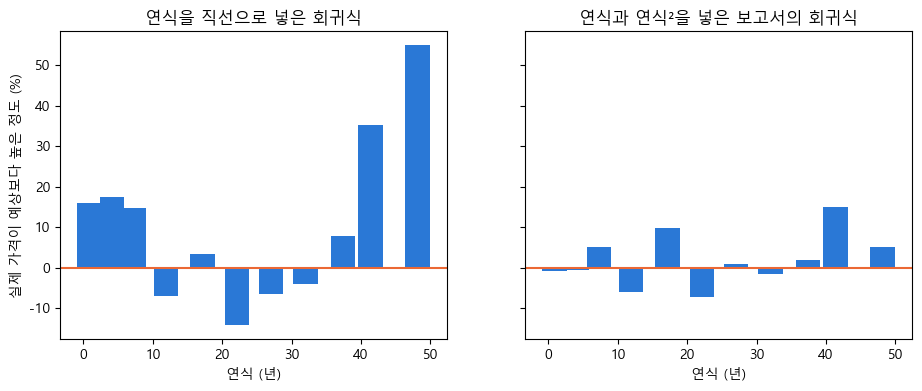

In [16]:
m_line = smf.ols('로그가격 ~ 로그면적 + 층 + 연식 + 직거래 + ' + GU, data=d).fit()   # 연식을 직선으로만

bins = [-1, 2, 5, 9, 14, 19, 24, 29, 34, 39, 44, 52]     # 연식 구간 경계
band = pd.cut(d['연식'], bins)
n = d['연식'].groupby(band, observed=True).size()                  # 구간별 거래 수
keep = n >= 100                                                     # 100건 미만 구간은 뺀다
mid = d['연식'].groupby(band, observed=True).mean()[keep]           # 구간의 평균 연식
left = m_line.resid.groupby(band, observed=True).mean()[keep]       # 직선 (로그 잔차 평균)
right = m.resid.groupby(band, observed=True).mean()[keep]           # 곡선(보고서)
left, right = (np.exp(left) - 1) * 100, (np.exp(right) - 1) * 100  # 로그 → %
print(pd.DataFrame({'직선(%)': left.round(0), '곡선(%)': right.round(0)}))

fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
ax[0].bar(mid, left, width=3.5, color='#2a78d6')
ax[0].set_title('연식을 직선으로 넣은 회귀식')
ax[1].bar(mid, right, width=3.5, color='#2a78d6')
ax[1].set_title('연식과 연식²을 넣은 보고서의 회귀식')
for a in ax:
    a.axhline(0, color='#eb6834')
    a.set_xlabel('연식 (년)')
ax[0].set_ylabel('실제 가격이 예상보다 높은 정도 (%)')
plt.show()

## 정리

이 노트북의 코드는 이 장에서 본 숫자와 그림을 직접 만들어 냈다. 보고서의 회귀 결과는 3절의 회귀식 한 줄과 `smf.ols(...).fit()`에서 나오고, 본문의 표와 그림은 그 회귀식에 변수를 더하거나 빼고(6, 9, 10절), 조건을 넣어 예상 가격을 계산한(5, 10절) 것이다.

자기 데이터로 분석하려면 1절의 `CSV` 파일 이름을 바꾸고, 3절의 기준 구(`'노원구'`)를 그 자료에 있는 지역 이름으로 바꾼 뒤 처음부터 다시 실행한다. AI가 만든 보고서를 받았다면, 이 코드로 같은 숫자가 나오는지 확인해 보는 것이 가장 확실한 점검이다.